In [2]:
### Uses 26.04-py3 docker container from nvidia for pytorch

In [2]:
%pip install matplotlib seaborn scikit-learn pandas opencv-python-headless tqdm scikit-learn torchcam

INFO: pip is looking at multiple versions of torchcam to determine which version is compatible with other requirements. This could take a while.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 16.4 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.4/60.4 MB 17.7 MB/s  0:00:03 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [seaborn]m5/6 [seaborn]earn]-headless]
Note: you may need to restart the kernel to use updated packages.


In [8]:
import torch
import torchvision
import cv2
import numpy as np

print(f"CUDA: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Device: {torch.cuda.get_device_name(0)}")
    
# Testing a simple GPU operation
test_tensor = torch.ones(1).cuda()
print("GPU computation successful!")

CUDA: True
Device: NVIDIA GeForce RTX 5070 Ti
GPU computation successful!


## CNN Model

In [4]:
import torch
import os
import gc
from tqdm import tqdm
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, ConcatDataset

# 1. Standard Transforms
transform = transforms.Compose([
    transforms.Resize((448, 448)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]) # Shifts the math!
])

base_path = 'Data/'
# Get the paths for Riboflavin_04_09, Riboflavin_04_15, etc.
date_folders = sorted([os.path.join(base_path, d) for d in os.listdir(base_path) 
                       if os.path.isdir(os.path.join(base_path, d))])

all_sub_datasets = []

for folder in date_folders:
    # This looks at 0.75, 1.5, etc. INSIDE each date folder
    sub_ds = datasets.ImageFolder(root=folder, transform=transform)
    all_sub_datasets.append(sub_ds)
    print(f"Loaded {folder}: {len(sub_ds)} images.")

# Combine them!
full_dataset = ConcatDataset(all_sub_datasets)

# Important: To get the class names, we look at the first sub-dataset
class_names = sorted(all_sub_datasets[0].classes, key=float)
num_classes = len(class_names)

# Split 70/30
train_size = int(0.7 * len(full_dataset))
test_size = len(full_dataset) - train_size
train_set, test_set = torch.utils.data.random_split(full_dataset, [train_size, test_size])

def fast_preload(subset, num_workers=8):
    """Uses parallel workers to load data into RAM much faster."""
    # Temporary loader just for pre-fetching
    temp_loader = DataLoader(subset, batch_size=1, num_workers=num_workers)
    
    samples = []
    print(f"Parallel pre-loading with {num_workers} workers...")
    
    for image, label in tqdm(temp_loader):
        # image is [1, 3, 224, 224], squeeze to [3, 224, 224]
        samples.append((image.squeeze(0), label.item()))
        
    return samples

# 1. Clear the Python garbage collector
gc.collect()

# 2. Clear the CUDA cache (empties the VRAM on your 5070 Ti)
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.ipc_collect() # Clears shared memory processes

print("RAM and VRAM cleared.")

train_cache = 'train_samples.pt'
test_cache = 'test_samples.pt'

if os.path.exists(train_cache) and os.path.exists(test_cache):
    print("Found cached tensors! Loading directly from disk...")
    train_samples = torch.load(train_cache)
    test_samples = torch.load(test_cache)
    print("Load complete. Tensors are ready in RAM.")
else:
    print("No cache found. Starting the RAM Pre-load from BMPs...")
    
    train_samples = fast_preload(train_set, num_workers=8)
    test_samples = fast_preload(test_set, num_workers=8)
    
    print("Caching tensors to disk for next time...")
    torch.save(train_samples, train_cache)
    torch.save(test_samples, test_cache)
    print("Successfully cached!")

# --- 2. Create the DataLoaders ---
# Note: Since the data is in RAM, we set num_workers=0. 
# Multiplying threads for RAM-based data often adds unnecessary overhead.
train_loader = DataLoader(
    train_samples, 
    batch_size=32, 
    shuffle=True, 
    num_workers=0, 
    pin_memory=True
)

test_loader = DataLoader(
    test_samples, 
    batch_size=32, 
    shuffle=False, 
    num_workers=0, 
    pin_memory=True
)
print(f"\nTOTAL: {len(full_dataset)} images across {num_classes} concentration classes.")
print(f"Classes: {class_names}")

Loaded Data/Riboflavin_04_09: 1717 images.
Loaded Data/Riboflavin_04_15: 680 images.
Loaded Data/Riboflavin_04_17: 2017 images.
RAM and VRAM cleared.
Found cached tensors! Loading directly from disk...
Load complete. Tensors are ready in RAM.

TOTAL: 4414 images across 8 concentration classes.
Classes: ['0.75', '1.5', '3', '6.25', '12.5', '25', '50', '100']


In [8]:
import torch.nn as nn
import torch.optim as optim
from torchvision import models

# 1. Load Pre-trained ResNet18
# Using the updated weights parameter
model = models.resnet50(weights='IMAGENET1K_V1')

# 2. Freeze the 'backbone'
# This speeds up training and prevents overfitting on your 4.4k images
for param in model.parameters():
    param.requires_grad = False

# 3. Replace the Final Layer
# We change the output features to match your num_classes
num_ftrs = model.fc.in_features
model.fc = nn.Linear(num_ftrs, num_classes)

# 4. Move to your 5070 Ti
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

# 5. Define Loss Function and Optimizer
# CrossEntropy is perfect for multi-class concentration labels
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
# We only train the weights of the final layer (model.fc)
optimizer = optim.Adam(model.fc.parameters(), lr=0.001)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.1, patience=2)

print(f"Model initialized for {num_classes} classes and moved to {device}.")

Model initialized for 8 classes and moved to cuda.


In [61]:
import time

num_epochs = 50  # Adjust based on performance

def get_lr(epoch):
    if epoch < 2:
        return 1e-3  # High power to "kick" the weights
    if epoch < 10:
        return 1e-4  # Standard training
    return 1e-5

for epoch in range(num_epochs):
    start_time = time.time()

    current_lr = get_lr(epoch)
    for param_group in optimizer.param_groups:
        param_group['lr'] = current_lr
    
    # --- TRAINING PHASE ---
    model.train()
    running_loss = 0.0
    running_corrects = 0

    train_transforms = transforms.Compose([
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomVerticalFlip(p=0.5),
        # transforms.ColorJitter(brightness=0.1, contrast=0.1) # Helps with lab lighting shifts
    ])
    
    for inputs, labels in tqdm(train_loader):
        inputs = train_transforms(inputs)
        inputs, labels = inputs.to(device), labels.to(device)

        # Zero the parameter gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)
        loss = criterion(outputs, labels)

        # Backward pass + optimize
        loss.backward()
        optimizer.step()

        # Statistics
        running_loss += loss.item() * inputs.size(0)
        running_corrects += torch.sum(preds == labels.data)

    epoch_loss = running_loss / len(train_set)
    epoch_acc = running_corrects.double() / len(train_set)

    # --- VALIDATION PHASE ---
    model.eval()
    val_loss = 0.0
    val_corrects = 0

    with torch.no_grad(): # Disable gradient calculation for efficiency
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * inputs.size(0)
            val_corrects += torch.sum(preds == labels.data)
            scheduler.step(val_loss)

    val_loss = val_loss / len(test_set)
    val_acc = val_corrects.double() / len(test_set)

    duration = time.time() - start_time
    print(f'Epoch {epoch+1}/{num_epochs} | '
          f'Train Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f} | '
          f'Val Loss: {val_loss:.4f} Acc: {val_acc:.4f} | '
          f'Time: {duration:.2f}s')

print("\nTraining Complete!")

100%|█████████████████████████████████████████████| 97/97 [00:15<00:00,  6.23it/s]


Epoch 1/50 | Train Loss: 1.1655 Acc: 0.6572 | Val Loss: 17.5512 Acc: 0.0823 | Time: 19.53s


100%|█████████████████████████████████████████████| 97/97 [00:15<00:00,  6.26it/s]


Epoch 2/50 | Train Loss: 0.9598 Acc: 0.7935 | Val Loss: 21.1071 Acc: 0.1088 | Time: 19.31s


100%|█████████████████████████████████████████████| 97/97 [00:15<00:00,  6.46it/s]


Epoch 3/50 | Train Loss: 0.8758 Acc: 0.8336 | Val Loss: 20.2014 Acc: 0.0808 | Time: 18.86s


... (90 outputs left out)

100%|█████████████████████████████████████████████| 97/97 [00:14<00:00,  6.53it/s]


Epoch 49/50 | Train Loss: 0.8336 Acc: 0.8647 | Val Loss: 23.1857 Acc: 0.1329 | Time: 18.81s


100%|█████████████████████████████████████████████| 97/97 [00:15<00:00,  6.39it/s]


Epoch 50/50 | Train Loss: 0.8258 Acc: 0.8669 | Val Loss: 24.4268 Acc: 0.1390 | Time: 19.03s

Training Complete!


In [ ]:
# print(f"Train Max: {train_samples[0][0].max()} | Test Max: {test_samples[0][0].max()}")

In [9]:
# torch.save(model.state_dict(), 'riboflavin_resnet50_v5.pth')
# print("Model weights saved to riboflavin_resnet50_v5.pth")

# to load back in
model.load_state_dict(torch.load('riboflavin_resnet50_v4.pth'))
model.eval() # Always set to eval mode after loading for predictions

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

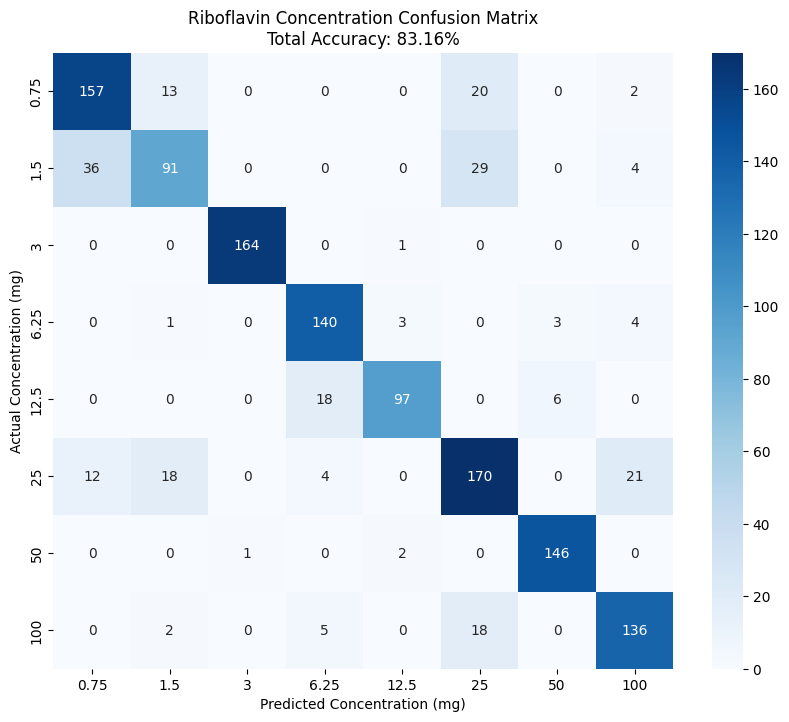

In [11]:
from sklearn.metrics import confusion_matrix, accuracy_score
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

all_preds = []
all_labels = []

model.eval()
with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)
        
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# Calculate overall accuracy
total_accuracy = accuracy_score(all_labels, all_preds)

# Calculate the matrix
cm = confusion_matrix(all_labels, all_preds)

# 1. Create a mapping of class names to their numerical values
numeric_classes = []
for name in class_names:
    try:
        numeric_classes.append(float(name))
    except ValueError:
        numeric_classes.append(name)

# 2. Get the sorted indices
sorted_indices = np.argsort(numeric_classes)
sorted_class_names = [class_names[i] for i in sorted_indices]

# 3. Reorder the confusion matrix rows and columns
cm_sorted = cm[sorted_indices, :]
cm_sorted = cm_sorted[:, sorted_indices]

# 4. Plot the sorted heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(cm_sorted, annot=True, fmt='d', cmap='Blues', 
            xticklabels=sorted_class_names, 
            yticklabels=sorted_class_names)

plt.xlabel('Predicted Concentration (mg)')
plt.ylabel('Actual Concentration (mg)')

# Include the accuracy in the title
plt.title(f'Riboflavin Concentration Confusion Matrix\nTotal Accuracy: {total_accuracy:.2%}')
plt.show()

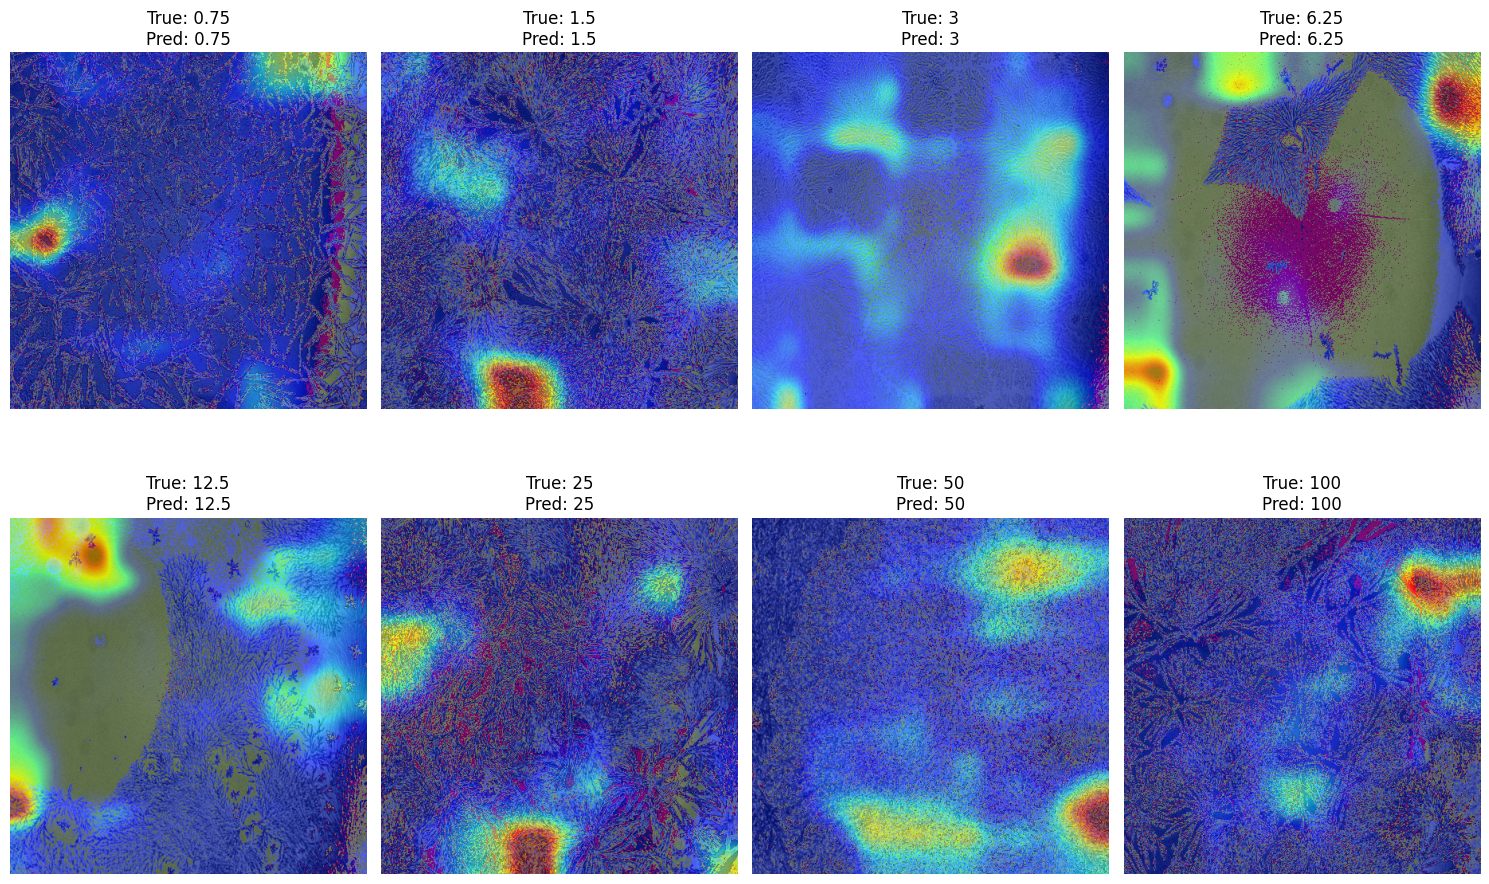

In [13]:
from torchcam.methods import GradCAM
from torchcam.utils import overlay_mask
from torchvision.transforms.functional import to_pil_image
import torch
import matplotlib.pyplot as plt
import math

# 1. Prepare Model (Ensure it's ready for gradients)
model.eval()
for param in model.parameters():
    param.requires_grad = True

cam_extractor = GradCAM(model, target_layer='layer4')

# 2. Find one sample image for each concentration
unique_images = {}
found_classes = set()

for imgs, lbls in test_loader:
    for i in range(len(lbls)):
        label = lbls[i].item()
        if label not in found_classes:
            unique_images[label] = imgs[i:i+1]
            found_classes.add(label)
    if len(found_classes) == len(sorted_class_names):
        break

# 3. Calculate Grid Dimensions for 3 Columns
cols = 4
rows = math.ceil(len(sorted_class_names) / cols)
fig, axes = plt.subplots(rows, cols, figsize=(15, 5 * rows))

# Flatten axes array for easy iteration if it's 2D
axes_flat = axes.flatten() if rows > 1 else axes

# 4. Generate and Plot
for idx, label_val in enumerate(sorted(unique_images.keys())):
    img_tensor = unique_images[label_val].to(device)
    
    # Forward pass
    out = model(img_tensor)
    pred_idx = out.squeeze(0).argmax().item()
    
    # Get Heatmap
    activation_map = cam_extractor(pred_idx, out)
    
    # Overlay logic
    img_pil = to_pil_image(img_tensor.squeeze(0).cpu())
    heatmap_pil = to_pil_image(activation_map[0].squeeze(0), mode='F')
    result = overlay_mask(img_pil, heatmap_pil, alpha=0.5)
    
    # Display on the specific grid cell
    axes_flat[idx].imshow(result)
    axes_flat[idx].set_title(f"True: {sorted_class_names[label_val]}\nPred: {sorted_class_names[pred_idx]}")
    axes_flat[idx].axis('off')

# Clean up empty subplots if classes aren't a multiple of 3
for j in range(idx + 1, len(axes_flat)):
    axes_flat[j].axis('off')

plt.tight_layout()
plt.show()

# Clean up hooks
cam_extractor.clear_hooks()